# **CNN 기초**

In [1]:
from sklearn import set_config
set_config(display="text")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.model_selection import train_test_split   #---- 문제답 분리


import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)
    
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D  #---- CNN
from keras.layers import Dense, Flatten        #---- FC

# **[실습1] CNN 모델**

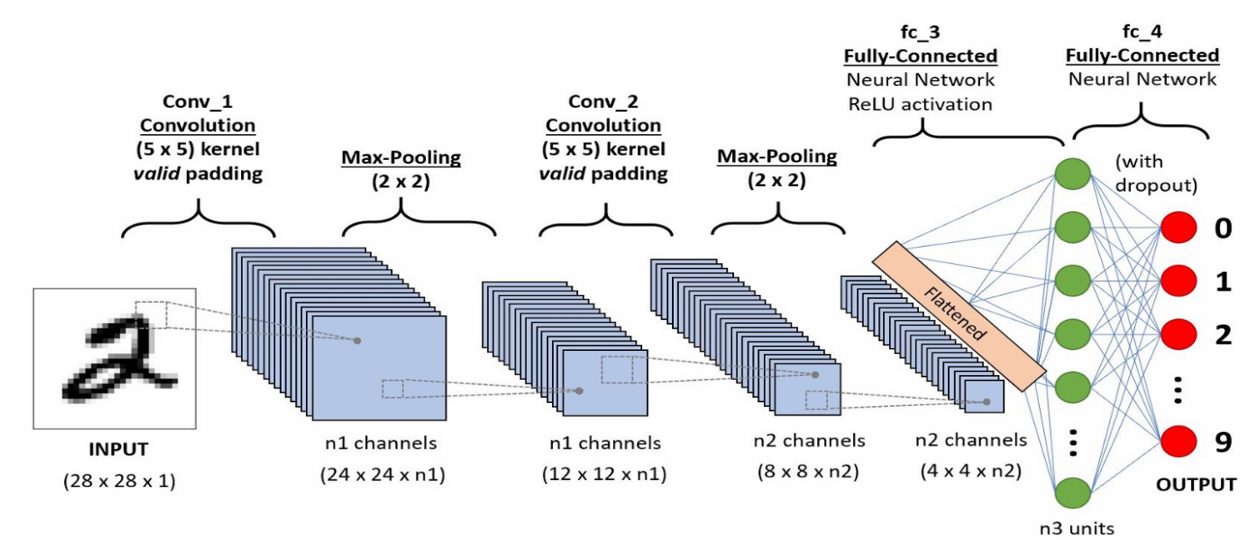

In [8]:
#Conv2D?
#MaxPooling2D?
#Dense?

In [13]:
from keras.datasets.fashion_mnist import load_data

In [14]:
(X_train, y_train), (X_test, y_test) = load_data()

In [15]:
X_train = X_train / 255.0
X_test  = X_test / 255.0

In [16]:
model = Sequential([
    Conv2D(filters=16, kernel_size=(5,5), strides=(1, 1), padding='valid', activation='relu', input_shape=(28,28,1)) ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Conv2D(filters=24, kernel_size=(5,5), strides=(1, 1), padding='valid', activation='relu') ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Flatten(),
    Dense(units=60,  activation='relu'),
    Dense(units=20,  activation='relu'),
    Dense(units=10,  activation='softmax')
])
model.compile(loss="sparse_categorical_crossentropy" , optimizer="adam",  metrics=['accuracy'] )

In [17]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)                   │ (None, 24, 24, 16)          │             416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_12 (MaxPooling2D)      │ (None, 12, 12, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 8, 8, 24)            │           9,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_13 (MaxPooling2D)      │ (None, 4, 4, 24)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 384)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 60)                  │          23,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 20)                  │           1,220 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 10)                  │             210 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,570 (135.04 KB)

 Trainable params: 34,570 (135.04 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
fit_res = model.fit(X_train, y_train, batch_size=256, epochs=40, validation_data=(X_test, y_test) )

Epoch 1/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9263 - loss: 0.2050 - val_accuracy: 0.9024 - val_loss: 0.2911
Epoch 2/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9276 - loss: 0.2006 - val_accuracy: 0.9026 - val_loss: 0.2926
Epoch 3/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9290 - loss: 0.1962 - val_accuracy: 0.9032 - val_loss: 0.2921
Epoch 4/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9299 - loss: 0.1927 - val_accuracy: 0.9031 - val_loss: 0.2927
Epoch 5/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9316 - loss: 0.1883 - val_accuracy: 0.9035 - val_loss: 0.2920
Epoch 6/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9326 - loss: 0.1841 - val_accuracy: 0.9031 - val_loss: 0.2940
Epoch 7/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9344 - loss: 0.1799 - val_accuracy: 0.9032 - val_loss: 0.2959
Epoch 8/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9354 - loss: 0.1764 - val_accuracy: 0.

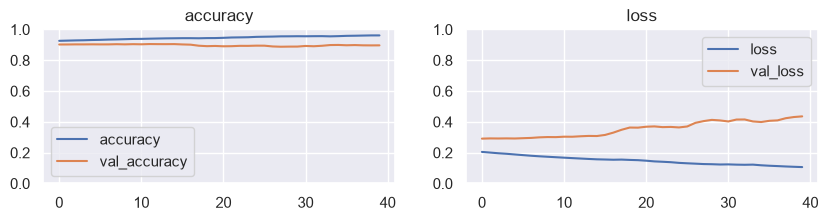

In [20]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['accuracy']   ,   label="accuracy")
ax1.plot(fit_res.history['val_accuracy'],  label="val_accuracy")
ax1.legend()
ax1.set_ylim(0, 1.0)
ax1.set_title("accuracy")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['loss']   ,   label="loss")
ax2.plot(fit_res.history['val_loss'],  label="val_loss")
ax2.legend()
ax2.set_ylim(0, 1.0)
ax2.set_title("loss")

plt.show()


In [21]:
res = model.evaluate(X_test, y_test)
print(f"accuracy : {res[1]:.4f} ")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8969 - loss: 0.4357
accuracy : 0.8969 


# **[실습2] CNN 모델**

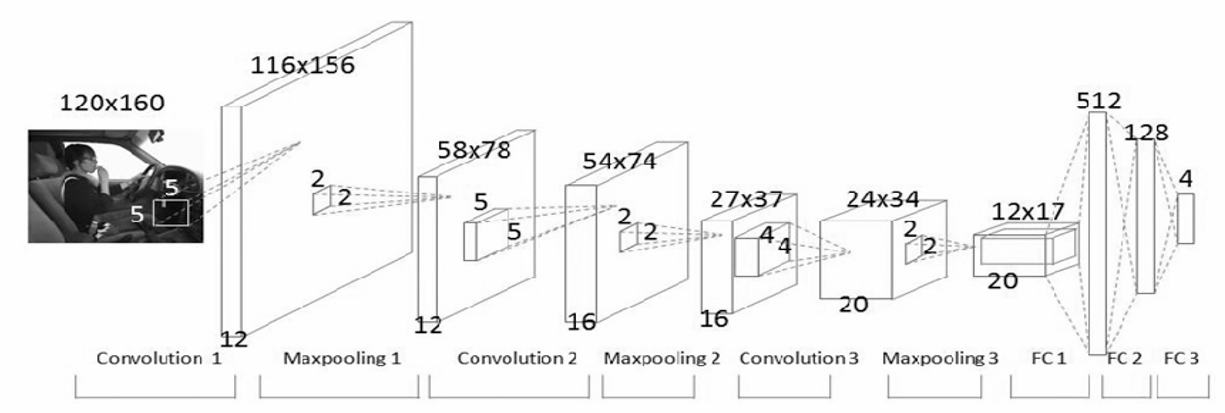

In [22]:
model = Sequential([
    Conv2D(filters=12, kernel_size=(5,5), strides=(1, 1), padding='valid', activation='relu', input_shape=(120,160,1)) ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Conv2D(filters=16, kernel_size=(5,5), strides=(1, 1), padding='valid', activation='relu') ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Conv2D(filters=20, kernel_size=(4,4), strides=(1, 1), padding='valid', activation='relu') ,    
    MaxPooling2D(pool_size=(2, 2)) ,
    Flatten(),
    Dense(units=512, activation='relu'),
    Dense(units=128, activation='relu'),
    Dense(units=4,   activation='softmax')
])
model.compile(loss="sparse_categorical_crossentropy" , optimizer="adam",  metrics=['accuracy'] )


In [23]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)                   │ (None, 116, 156, 12)        │             312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_14 (MaxPooling2D)      │ (None, 58, 78, 12)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 54, 74, 16)          │           4,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_15 (MaxPooling2D)      │ (None, 27, 37, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_18 (Conv2D)                   │ (None, 24, 34, 20)          │           5,140 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_16 (MaxPooling2D)      │ (None, 12, 17, 20)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 4080)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 512)                 │       2,089,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,165,920 (8.26 MB)

 Trainable params: 2,165,920 (8.26 MB)

 Non-trainable params: 0 (0.00 B)